# Assignment 4: logistic regression (Daniel)
L1 (lasso) logistic regression on the 89 anterior cingulate libraries from Assignment 3.
The L1 penalty sets most gene weights to zero, so the genes left over are the model's signature (needed for step 5).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")  # hides scikit-learn deprecation messages

## Step 1: load the data from Assignment 2 (same samples and filtering as Assignment 3)

In [2]:
expr = pd.read_csv("data/expr_by_library.tsv.gz", sep="\t", index_col=0)
meta = pd.read_csv("data/meta_by_library.tsv", sep="\t", index_col=0)

meta = meta[meta.region == "ancg"]                 # 89 anterior cingulate libraries
log_expr = np.log2(expr[meta.index] + 1)
log_expr = log_expr[log_expr.median(axis=1) > 0]   # drop genes that are basically off
genes_by_variance = log_expr.var(axis=1).sort_values(ascending=False).index

## Step 2: the two things to predict
- **group** (Assignment 1): 1 = any disorder, 0 = control
- **cluster** (my Assignment 3 hierarchical clustering, k = 2): 1 = the 15 library subgroup, 0 = the other 74.
  With only two clusters, "one cluster vs all others" is just subgroup vs rest.

In [3]:
clusters = pd.read_csv("results/a3_labels_hclust.tsv", sep="\t", index_col=0).loc[meta.index, "g5000_k2"]
subgroup = clusters.value_counts().idxmin()        # the smaller cluster

y = {
    "group": (meta.dx != "control").astype(int),
    "cluster": (clusters == subgroup).astype(int),
}
print(y["group"].value_counts(), y["cluster"].value_counts())

dx
1    67
0    22
Name: count, dtype: int64 g5000_k2
0    74
1    15
Name: count, dtype: int64


## Steps 2 and 4: train with 10 to 10,000 genes
`cross_val_predict` splits the libraries into 5 folds and predicts each fold with a model trained on the other 4,
so every library is predicted by a model that never saw it. C = 0.1 sets how strong the L1 penalty is.

In [4]:
def make_model():
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l1", solver="liblinear", C=0.1, class_weight="balanced"),
    )

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
predictions = pd.DataFrame(index=meta.index)
auc_rows = []

for n in [10, 100, 1000, 5000, 10000]:
    X = log_expr.loc[genes_by_variance[:n]].T      # rows = libraries, columns = genes
    for target in ["group", "cluster"]:
        prob = cross_val_predict(make_model(), X, y[target], cv=cv, method="predict_proba")[:, 1]
        predictions[f"{target}_pred_g{n}"] = (prob >= 0.5).astype(int)
        auc_rows.append({"genes": n, "target": target, "AUC": roc_auc_score(y[target], prob)})

auc = pd.DataFrame(auc_rows)
auc.to_csv("results/a4_logreg_auc.tsv", sep="\t", index=False)
predictions.to_csv("results/a4_predictions_logreg.tsv", sep="\t")
auc.pivot(index="genes", columns="target", values="AUC").round(3)

target,cluster,group
genes,,
10,0.926,0.500
100,0.966,0.569
1000,0.994,0.475
5000,0.996,0.514
10000,0.995,0.509


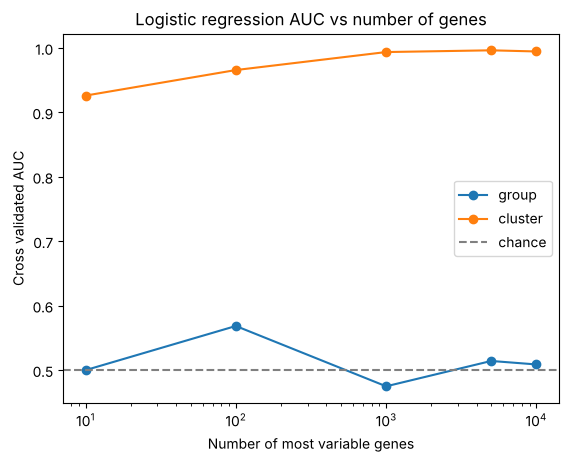

In [5]:
for target in ["group", "cluster"]:
    d = auc[auc.target == target]
    plt.plot(d.genes, d.AUC, marker="o", label=target)
plt.axhline(0.5, color="gray", linestyle="--", label="chance")
plt.xscale("log")
plt.xlabel("Number of most variable genes")
plt.ylabel("Cross validated AUC")
plt.title("Logistic regression AUC vs number of genes")
plt.legend()
plt.savefig("plots/a4_logreg_auc_by_genes.png", dpi=200, bbox_inches="tight")
plt.show()

## Signature genes for the step 5 heatmap
Fit each model on all 89 libraries with 5,000 genes and keep the genes with a nonzero weight.

In [6]:
symbols = pd.read_csv("gene_symbols.tsv", sep="\t", index_col=0)["symbol"]
X = log_expr.loc[genes_by_variance[:5000]].T
rows = []
for target in ["group", "cluster"]:
    weights = make_model().fit(X, y[target])[-1].coef_[0]
    for gene, w in zip(X.columns, weights):
        if w != 0:
            rows.append({"gene": gene, "symbol": symbols.get(gene), "coef": w, "target": target, "method": "logreg"})

signature = pd.DataFrame(rows)
signature.to_csv("results/a4_signature_logreg.tsv", sep="\t", index=False)
signature.groupby("target").size()

target
cluster    18
group      13
dtype: int64